## 1. Planteamiento del problema

Con  $U_\theta(x,y,t) = \sin(\pi x)\sin(\pi y)\,a_\theta(t)$, la ecuación de ondas se reduce a:

$$a''(t) + 2\pi^2 a(t) = 0, \qquad a(0) = 1, \qquad a'(0) = \sqrt{2}\pi,$$

cuya solución analítica es (ver notas)

$$a(t) = \sqrt{2}\,\sin\!\left(\sqrt{2}\pi t + \frac{\pi}{4}\right).$$

Las condiciones de frontera se satisfacen idénticamente por el factor $\sin(\pi x)\sin(\pi y)$.

En este caso se va a entrenar en el intervalo $t \in [0, T]$ con $T = 2$, usando $N = 200$ puntos. Los pesos de las condiciones iniciales son $\omega_0 = \omega_1 = 100$.

In [3]:
import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt

PI = np.pi
W0 = np.sqrt(2) * PI           # frecuencia natural
A0, V0 = 1.0, np.sqrt(2) * PI  # a(0) y a'(0)
T = 2.0                        # intervalo [0, T]
N = 200                        # puntos de colocación
t_col = np.linspace(0, T, N)
w_ini0, w_ini1 = 100.0, 100.0  # pesos de las condiciones iniciales

def a_exacta(t):
    return np.sqrt(2) * np.sin(W0 * t + PI / 4)

## 2. Modelo A: una capa con dos neuronas sinusoidales

$$a_\theta(t) = \sum_{j=1}^{2} A_j \sin(w_j t + b_j), \qquad \theta = \{A_1, w_1, b_1, A_2, w_2, b_2\}$$

Derivadas analíticas respecto a $t$:

$$a_\theta'(t) = \sum_{j=1}^{2} A_j w_j \cos(w_j t + b_j), \qquad a_\theta''(t) = -\sum_{j=1}^{2} A_j w_j^2 \sin(w_j t + b_j)$$

La función devuelve $a_\theta$, $a_\theta'$ y $a_\theta''$ evaluadas en los tiempos `t`.

In [4]:
def modelo_A(p, t):
    A1, w1, b1, A2, w2, b2 = p
    a   =  A1*np.sin(w1*t + b1)       + A2*np.sin(w2*t + b2) # Ecuación [7]
    da  =  A1*w1*np.cos(w1*t + b1)    + A2*w2*np.cos(w2*t + b2) # Ecuación [8]
    d2a = -A1*w1**2*np.sin(w1*t + b1) - A2*w2**2*np.sin(w2*t + b2) # Ecuación [9]
    return a, da, d2a

In [5]:
p_prueba = [np.sqrt(2), W0, PI/4, 0, 1, 0]
a, da, d2a = modelo_A(p_prueba, t_col)
print("residuo máximo:", np.max(np.abs(d2a + 2*PI**2*a)))   # ≈ 1e-13
print("a(0) =", a[0], "  a'(0) =", da[0])                    # ≈ 1 y ≈ 4.443

residuo máximo: 3.552713678800501e-15
a(0) = 1.0000000000000002   a'(0) = 4.442882938158367


## 3. Modelo B: dos capas con una neurona cada una

$$h_1(t) = \sin(w_1 t + b_1), \qquad a_\theta(t) = A\sin\big(u(t)\big), \qquad u(t) = w_2 h_1(t) + b_2$$

con $\theta = \{w_1, b_1, w_2, b_2, A\}$.

Derivadas analíticas respecto a $t$ (regla de la cadena y del producto):

$$a_\theta'(t) = A\,w_1 w_2 \cos(w_1 t + b_1)\cos(u)$$

$$a_\theta''(t) = -A\,w_1^2 w_2^2 \cos^2(w_1 t + b_1)\sin(u) - A\,w_1^2 w_2\, h_1(t)\cos(u)$$

In [ ]:
def modelo_B(p, t):
    w1, b1, w2, b2, A = p
    h1  = np.sin(w1*t + b1)          # primera neurona
    c1  = np.cos(w1*t + b1)
    u   = w2*h1 + b2                 # entrada de la segunda neurona
    a   = A*np.sin(u)
    da  = A*w1*w2*c1*np.cos(u) # Ecuación [11]
    d2a = -A*w1**2*w2**2*c1**2*np.sin(u) - A*w1**2*w2*h1*np.cos(u) # Ecuación [12]
    return a, da, d2a

In [7]:
p_prueba = [3.0, 0.5, 0.8, 0.2, 1.5]          # parámetros cualesquiera
a, da, d2a = modelo_B(p_prueba, t_col)

dt = t_col[1] - t_col[0]
da_num  = np.gradient(a, dt)                  # derivada numérica
d2a_num = np.gradient(da_num, dt)

print("diferencia máx. en a' :", np.max(np.abs(da - da_num)[2:-2]))
print("diferencia máx. en a'':", np.max(np.abs(d2a - d2a_num)[2:-2]))

diferencia máx. en a' : 0.0008955394180043541
diferencia máx. en a'': 0.009216239373996515


## 4. Función de pérdida

Se establece en tonces la función de pérdida dada por la ecuación [6] a partir de la ecuación [3] de las notas:

$$r_\theta(t) = a_\theta''(t) + 2\pi^2 a_\theta(t)$$

$$J(\theta) = \frac{1}{N}\sum_{k=1}^{N} r_\theta(t_k)^2 + \omega_0\big(a_\theta(0) - 1\big)^2 + \omega_1\big(a_\theta'(0) - \sqrt{2}\pi\big)^2$$



In [8]:
def perdida(p, modelo):
    a, _, d2a = modelo(p, t_col)
    r = d2a + 2*PI**2*a                          # residuo físico
    a_0, da_0, _ = modelo(p, np.array([0.0]))    # red evaluada en t = 0
    return (np.mean(r**2)
            + w_ini0*(a_0[0] - A0)**2
            + w_ini1*(da_0[0] - V0)**2)

In [ ]:
p_exacto = [np.sqrt(2), W0, PI/4, 0, 1, 0]
print("J con la solución exacta:", perdida(p_exacto, modelo_A))       # debe dar aproximadamente 0
print("J con parámetros al azar:", perdida([1, 2, 0, 1, 3, 0], modelo_A))  # grande

J con la solución exacta: 8.664011558979752e-29
J con parámetros al azar: 385.1487982021917


## 5. Minimización de las funciones de pérdida

Se busca $\min_\theta J(\theta)$ con el método BFGS (`scipy.optimize.minimize`), un método que usa el gradiente de $J$ respecto a los parámetros.



In [10]:
def entrenar(modelo, n_par, n_intentos=40, semilla=0):
    rng = np.random.default_rng(semilla)
    mejor = None
    for _ in range(n_intentos):
        p0 = rng.uniform(-2, 2, n_par)     # inicialización aleatoria
        res = minimize(perdida, p0, args=(modelo,), method="BFGS",
                       options={"maxiter": 5000, "gtol": 1e-10})
        if mejor is None or res.fun < mejor.fun:
            mejor = res
    return mejor

res_A = entrenar(modelo_A, 6, semilla=1)
res_B = entrenar(modelo_B, 5, semilla=2)

print("Modelo A: J =", f"{res_A.fun:.3e}")
print("  [A1, w1, b1, A2, w2, b2] =", np.round(res_A.x, 4))
print("Modelo B: J =", f"{res_B.fun:.3e}")
print("  [w1, b1, w2, b2, A]      =", np.round(res_B.x, 4))

Modelo A: J = 3.005e-13
  [A1, w1, b1, A2, w2, b2] = [ 0.6581 -4.4429  0.5044  1.7173 -4.4429 -3.55  ]
Modelo B: J = 4.001e-05
  [w1, b1, w2, b2, A]      = [4.44290e+00 7.85300e-01 3.13000e-02 0.00000e+00 4.52486e+01]


## 6. Cuantificación de errores y energía mecánica

Se evalúan ambos modelos en 1000 puntos de $[0, T]$ y se calculan:

- Error máximo: $\max_t |a_\theta(t) - a(t)|$
- Error relativo L2: $\|a_\theta - a\|_2 / \|a\|_2$
- Residuo RMS: $\sqrt{\frac{1}{N}\sum r_\theta^2}$

Para la energía, sustituyendo el ansatz en $E(t)$ e integrando en $x$ e $y$:

$$E(t) = \frac{1}{8}\Big[a'(t)^2 + 2\pi^2 a(t)^2\Big], \qquad E_{\text{exacta}} = \frac{\pi^2}{2} \approx 4.9348$$





In [11]:
t = np.linspace(0, T, 1000)
a_ex = a_exacta(t)
resultados = {}

for nombre, modelo, res in [("A", modelo_A, res_A), ("B", modelo_B, res_B)]:
    a, da, d2a = modelo(res.x, t)
    r = d2a + 2*PI**2*a
    E = (da**2 + 2*PI**2*a**2) / 8
    resultados[nombre] = dict(a=a, r=r, E=E)
    print(f"\nModelo {nombre}:")
    print(f"  error máximo      = {np.max(np.abs(a - a_ex)):.3e}")
    print(f"  error relativo L2 = {np.linalg.norm(a - a_ex)/np.linalg.norm(a_ex):.3e}")
    print(f"  residuo RMS       = {np.sqrt(np.mean(r**2)):.3e}")
    print(f"  variación máxima de E respecto a π²/2 = {np.max(np.abs(E - PI**2/2)):.3e}")

print(f"\nEnergía exacta = π²/2 = {PI**2/2:.4f}")


Modelo A:
  error máximo      = 1.215e-07
  error relativo L2 = 5.667e-08
  residuo RMS       = 5.438e-07
  variación máxima de E respecto a π²/2 = 1.143e-06

Modelo B:
  error máximo      = 1.567e-04
  error relativo L2 = 6.414e-05
  residuo RMS       = 6.299e-03
  variación máxima de E respecto a π²/2 = 1.496e-03

Energía exacta = π²/2 = 4.9348


## 7. Comparación gráfica

1. $a_\theta(t)$ de ambos modelos frente a la solución analítica.
2. Error absoluto $|a_\theta - a|$ en escala logarítmica.
3. Energía mecánica $E(t)$ frente al valor exacto $\pi^2/2$.
4. Residuo físico $r_\theta(t)$.

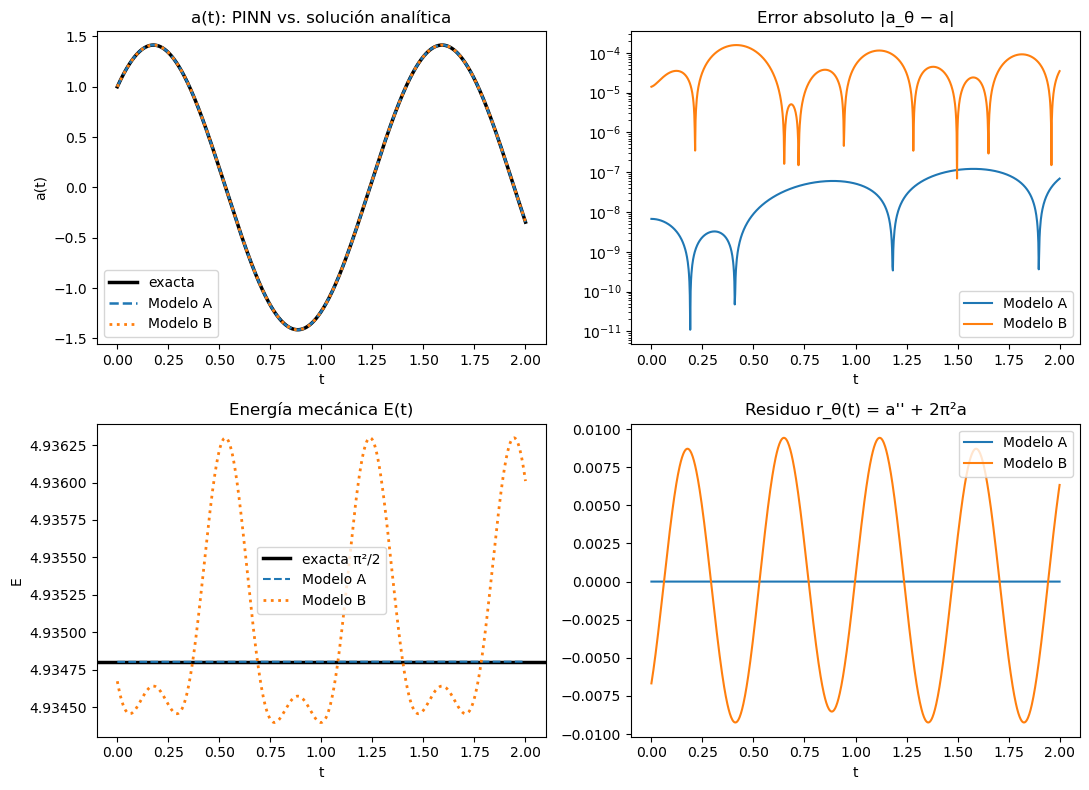

In [12]:
fig, ax = plt.subplots(2, 2, figsize=(11, 8))

# 1. a(t)
ax[0, 0].plot(t, a_ex, "k-", lw=2.5, label="exacta")
ax[0, 0].plot(t, resultados["A"]["a"], "--", c="tab:blue", lw=1.8, label="Modelo A")
ax[0, 0].plot(t, resultados["B"]["a"], ":", c="tab:orange", lw=2, label="Modelo B")
ax[0, 0].set(title="a(t): PINN vs. solución analítica", xlabel="t", ylabel="a(t)")
ax[0, 0].legend()

# 2. Error absoluto
ax[0, 1].semilogy(t, np.abs(resultados["A"]["a"] - a_ex) + 1e-16, c="tab:blue", label="Modelo A")
ax[0, 1].semilogy(t, np.abs(resultados["B"]["a"] - a_ex) + 1e-16, c="tab:orange", label="Modelo B")
ax[0, 1].set(title="Error absoluto |a_θ − a|", xlabel="t")
ax[0, 1].legend()

# 3. Energía
ax[1, 0].axhline(PI**2/2, c="k", lw=2.5, label="exacta π²/2")
ax[1, 0].plot(t, resultados["A"]["E"], "--", c="tab:blue", label="Modelo A")
ax[1, 0].plot(t, resultados["B"]["E"], ":", c="tab:orange", lw=2, label="Modelo B")
ax[1, 0].set(title="Energía mecánica E(t)", xlabel="t", ylabel="E")
ax[1, 0].legend()

# 4. Residuo
ax[1, 1].plot(t, resultados["A"]["r"], c="tab:blue", label="Modelo A")
ax[1, 1].plot(t, resultados["B"]["r"], c="tab:orange", label="Modelo B")
ax[1, 1].set(title="Residuo r_θ(t) = a'' + 2π²a", xlabel="t")
ax[1, 1].legend()

plt.tight_layout()
plt.show()

## 8. Análisis de resultados

Ambos modelos reproducen bien la solución analítica; en la gráfica de $a(t)$ las tres curvas prácticamente se superponen. La diferencia aparece al mirar los errores.

El modelo A llega a un error del orden de $10^{-7}$ y un residuo prácticamente nulo. Esto podría deberse a que las dos neuronas convergen a $|w_j| = \sqrt{2}\pi$, lo cual coincide con la frecuencia que anula el residuo, así que la red puede escribir la solución exacta como una suma de senos.

El modelo B tiene un error mayor, cercano a $10^{-4}$, y un residuo que oscila con amplitud de alrededor de $10^{-2}$. 

La energía en el modelo A se mantiene constante en $\pi^2/2 \approx 4.935$, mientras que en el modelo B oscila al mismo ritmo que su residuo. Esto muestra que la conservación de la energía es una buena forma de verificar si la PINN realmente cumple la física del problema.

Podría decirse que tener más capas no garantiza un mejor resultado. La arquitectura más simple funciona mejor porque su forma coincide con la de la solución.